In [1]:
import pandas as pd
import seaborn as sns

In [4]:
df = pd.read_csv("/Users/turfdiddy/Desktop/amz_uk_price_prediction_dataset.csv")

# Preview the first few rows
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [6]:
crosstab_result=pd.crosstab(df['category'], df['isBestSeller'])

In [7]:
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [8]:
# Sort by the proportion of bestsellers
crosstab_result_sorted = crosstab_result.sort_values(by='bestseller_rate', ascending=False)
print(crosstab_result_sorted.head(10))

KeyError: 'bestseller_rate'

In [9]:
# Step 1: Create the crosstab again if not already done
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

# Step 2: Add bestseller_rate column
crosstab_result['bestseller_rate'] = crosstab_result[True] / (crosstab_result[True] + crosstab_result[False])

# Step 3: Sort by bestseller_rate
crosstab_result_sorted = crosstab_result.sort_values(by='bestseller_rate', ascending=False)

# Step 4: Display top 10 categories with highest proportion of bestsellers
print(crosstab_result_sorted.head(10))

isBestSeller                    False  True  bestseller_rate
category                                                    
Grocery                          9008   556         0.058135
Smart Home Security & Lighting     98     6         0.057692
Health & Personal Care           9017   552         0.057686
Mobile Phone Accessories          248    11         0.042471
Power & Hand Tools               8353   306         0.035339
Billiard, Snooker & Pool          241     8         0.032129
Pet Supplies                     9152   285         0.030200
Home Brewing & Wine Making        239     7         0.028455
Wind Instruments                  243     7         0.028000
Mirrors                           243     7         0.028000


In [10]:
# 2. Add a column for total listings per category
crosstab_result['total'] = crosstab_result[False] + crosstab_result[True]

# 3. Calculate the proportion of bestsellers per category
crosstab_result['bestseller_rate'] = crosstab_result[True] / crosstab_result['total']

# 4. Sort by bestseller_rate in descending order
crosstab_result_sorted = crosstab_result.sort_values(by='bestseller_rate', ascending=False)

# 5. Display the top 10 categories with the highest bestseller rates
print(crosstab_result_sorted.head(10))

isBestSeller                    False  True  bestseller_rate  total
category                                                           
Grocery                          9008   556         0.058135   9564
Smart Home Security & Lighting     98     6         0.057692    104
Health & Personal Care           9017   552         0.057686   9569
Mobile Phone Accessories          248    11         0.042471    259
Power & Hand Tools               8353   306         0.035339   8659
Billiard, Snooker & Pool          241     8         0.032129    249
Pet Supplies                     9152   285         0.030200   9437
Home Brewing & Wine Making        239     7         0.028455    246
Wind Instruments                  243     7         0.028000    250
Mirrors                           243     7         0.028000    250


In [11]:
from scipy.stats import chi2_contingency

In [12]:
crosstab_result


isBestSeller,False,True,bestseller_rate,total
category,,,,
3D Printers,247,1,0.004032,248
3D Printing & Scanning,4065,2,0.000492,4067
Abrasive & Finishing Products,245,5,0.020000,250
Action Cameras,1696,1,0.000589,1697
Adapters,251,3,0.011811,254
...,...,...,...,...
Wind Instruments,243,7,0.028000,250
Window Treatments,234,5,0.020921,239
Women,17559,213,0.011985,17772


In [ ]:
# Chi-square test for 'isBestSeller' and 'category'
_, chi2_pvalue, _, _  = chi2_contingency(crosstab_result)

In [14]:
type(chi2_pvalue)

numpy.float64

In [15]:
float(chi2_pvalue)

0.0

In [16]:
float(chi2_pvalue) < 0.05

True

H₀: The two categorical variables are independent.
(There is no association between them.)
The null hypothesis of the Chi-square test is that the two categorical variables are independent. Given the extremely low \( p \)-value, we reject the null hypothesis. This implies that there's a significant association between `isBestSeller` and `category` in the dataset.

<Axes: xlabel='category'>

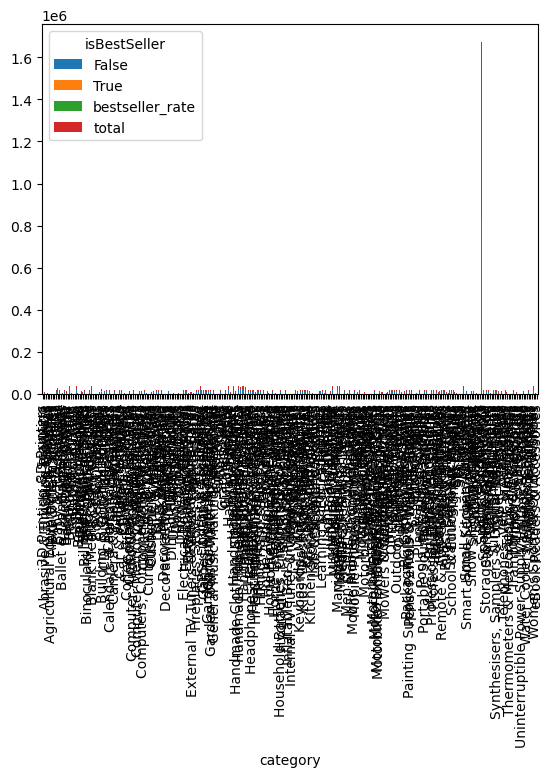

In [20]:
crosstab_result.plot(kind='bar', stacked=True)

<Axes: xlabel='category'>

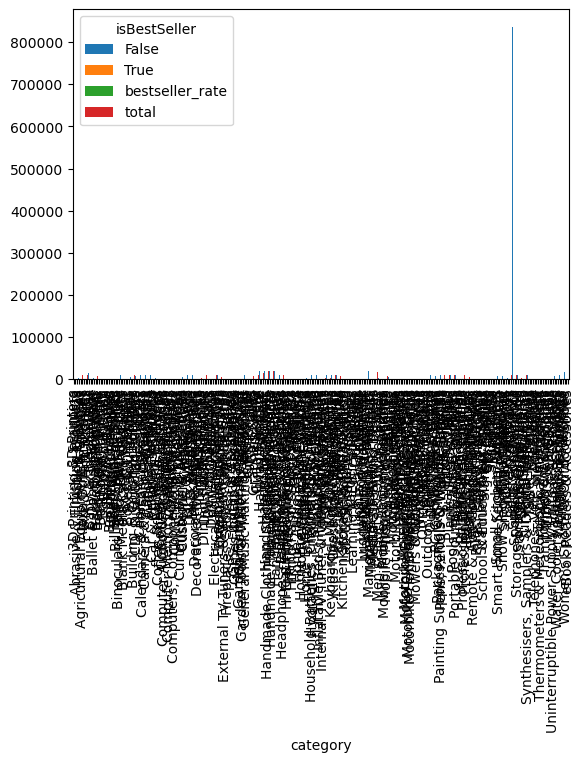

In [25]:
crosstab_result.plot(kind='bar')


In [27]:
import pandas as pd

# Assume your DataFrame is named df and the column of interest is 'price'

# 1. Calculate the IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# 2. Define lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Filter the dataframe
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

# 4. Optional: Check how many rows were removed
print(f"Original rows: {df.shape[0]}")
print(f"Rows after outlier removal: {df_no_outliers.shape[0]}")

Original rows: 2443651
Rows after outlier removal: 2115963


In [28]:
top_20_categories = df_no_outliers['category'].value_counts().head(20).index
df_top_20 = df_no_outliers[df_no_outliers['category'].isin(top_20_categories)]

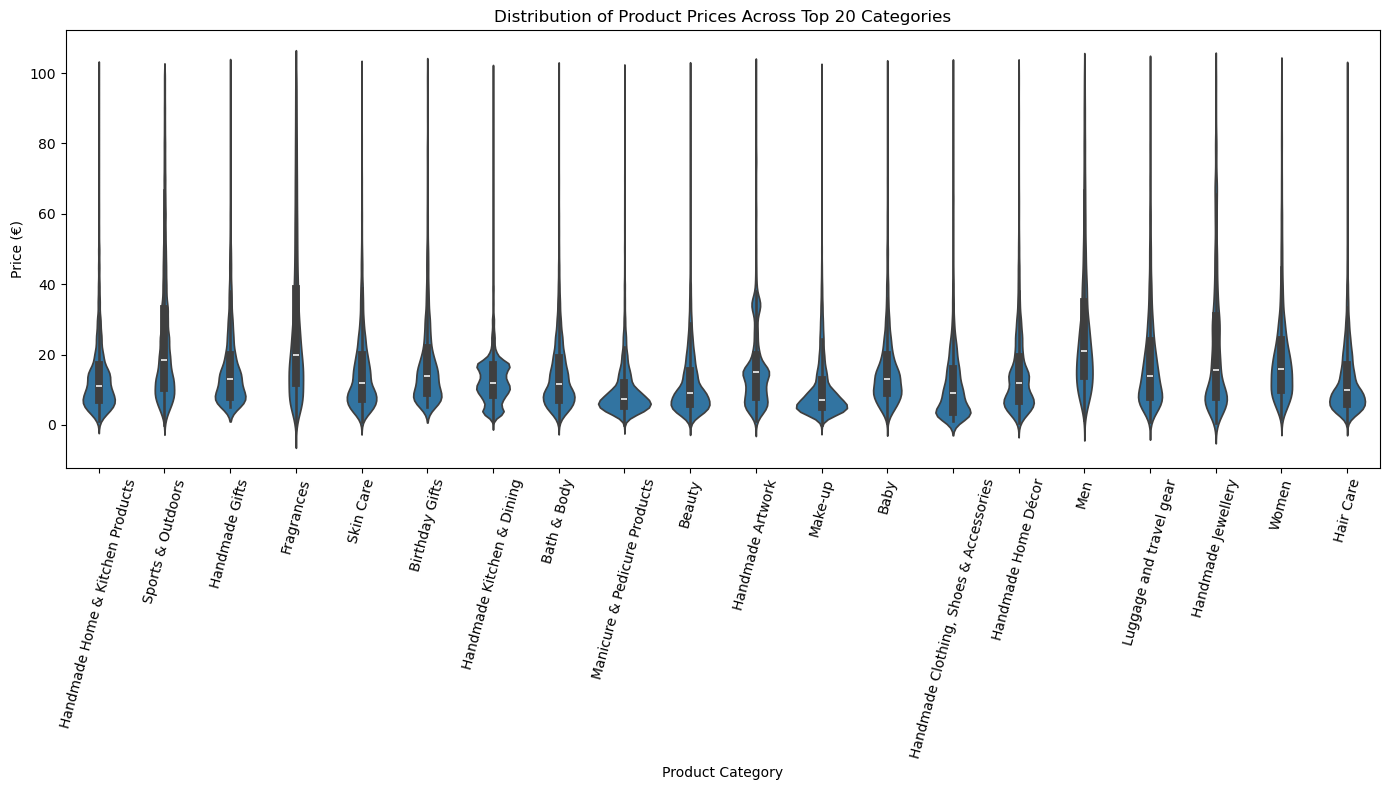

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 8))
sns.violinplot(data=df_top_20, x='category', y='price')
plt.xticks(rotation=75)
plt.title('Distribution of Product Prices Across Top 20 Categories')
plt.ylabel('Price (€)')
plt.xlabel('Product Category')
plt.tight_layout()
plt.show()

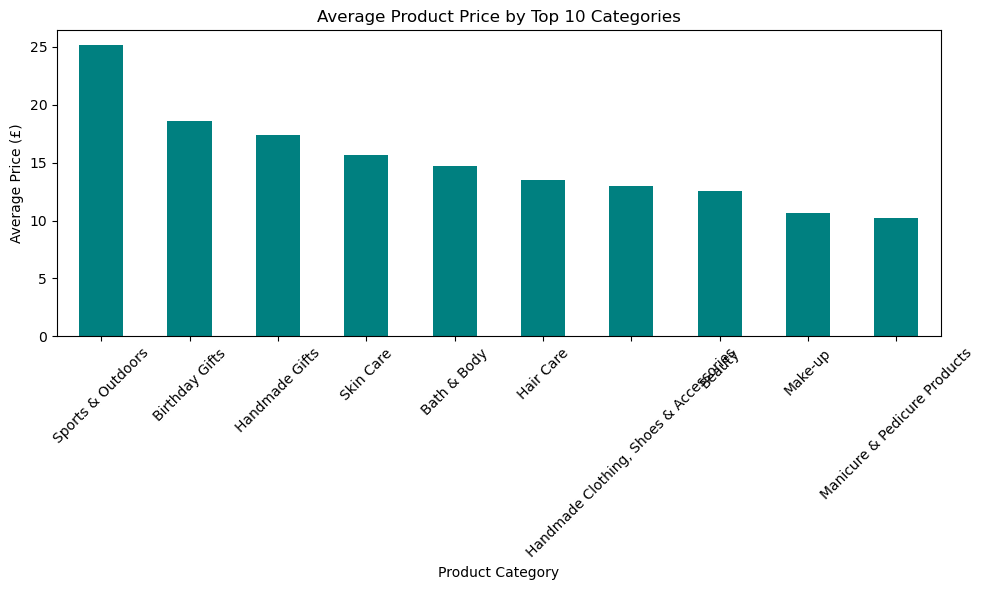

In [30]:
# Step 1: Identify top 10 categories by listing count
top_10_categories = df_no_outliers['category'].value_counts().head(10).index

# Step 2: Filter data to include only those top 10 categories
df_top_10 = df_no_outliers[df_no_outliers['category'].isin(top_10_categories)]

# Step 3: Calculate average price per category
avg_price_by_category = df_top_10.groupby('category')['price'].mean().sort_values(ascending=False)

# Step 4: Plot the bar chart
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
avg_price_by_category.plot(kind='bar', color='teal')
plt.title('Average Product Price by Top 10 Categories')
plt.ylabel('Average Price (£)')
plt.xlabel('Product Category')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


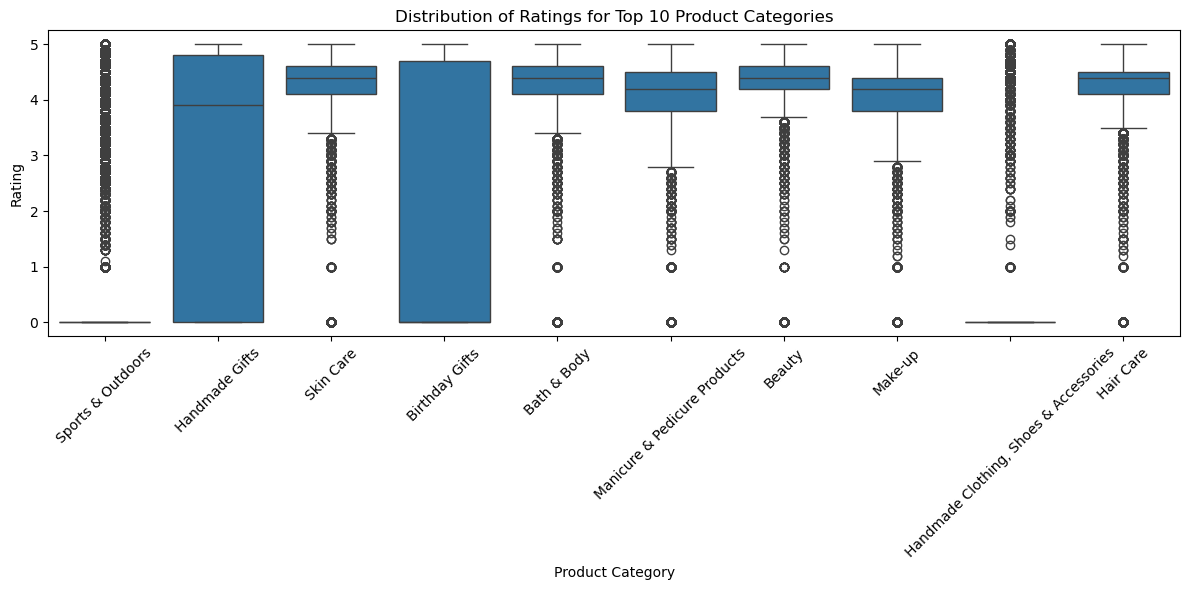

In [31]:

# Step 1: Identify the top 10 most frequent categories
top_10_categories = df_no_outliers['category'].value_counts().head(10).index

# Step 2: Filter dataset to only include those categories
df_top10_ratings = df_no_outliers[df_no_outliers['category'].isin(top_10_categories)]

# Step 3: Create box plot for ratings per category
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_top10_ratings, x='category', y='stars')
plt.title('Distribution of Ratings for Top 10 Product Categories')
plt.ylabel('Rating')
plt.xlabel('Product Category')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
# Calculate the correlation between price and rating
correlation = df_no_outliers['price'].corr(df_no_outliers['stars'])
print(f"Correlation coefficient between price and stars: {correlation:.3f}")

Correlation coefficient between price and stars: -0.078


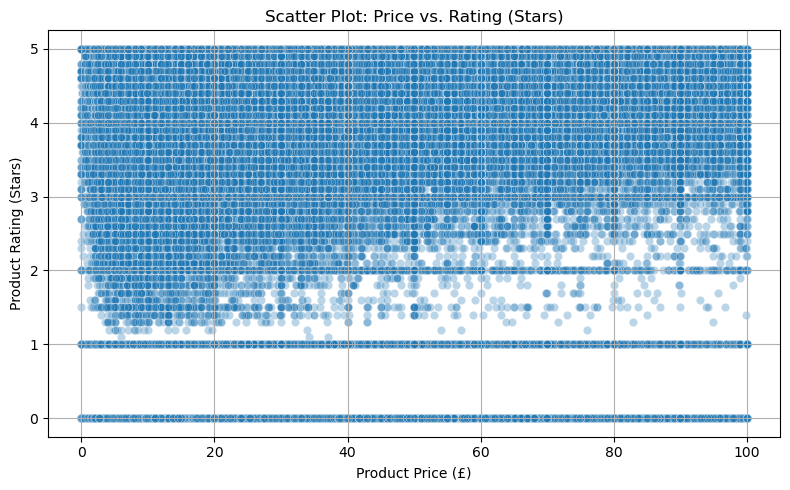

In [33]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_no_outliers, x='price', y='stars', alpha=0.3)
plt.title('Scatter Plot: Price vs. Rating (Stars)')
plt.xlabel('Product Price (£)')
plt.ylabel('Product Rating (Stars)')
plt.grid(True)
plt.tight_layout()
plt.show()

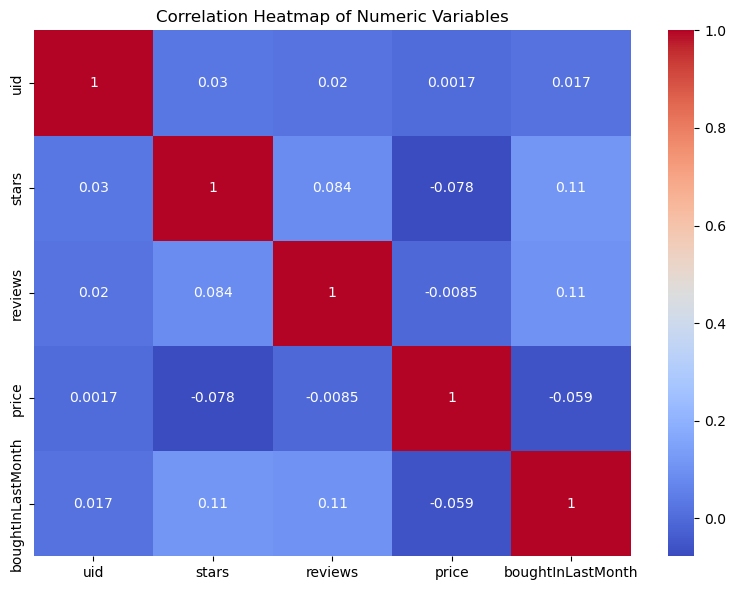

In [34]:
plt.figure(figsize=(8, 6))
sns.heatmap(df_no_outliers.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()


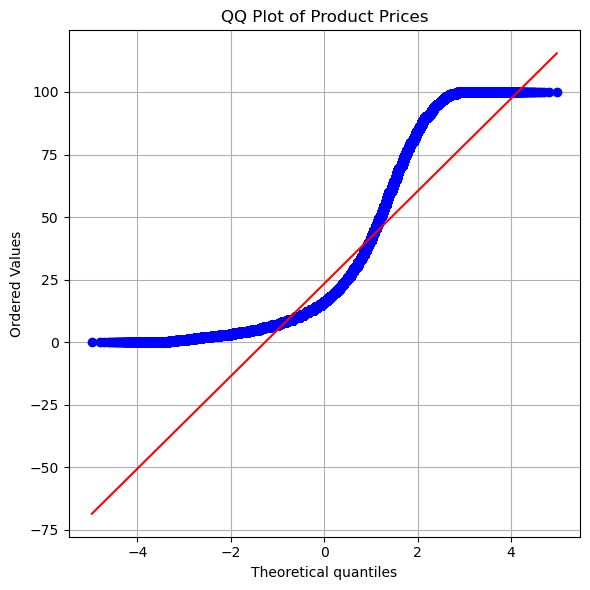

In [35]:
import scipy.stats as stats
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.grid(True)
plt.tight_layout()
plt.show()